In [4]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "serif",
    "figure.dpi": 300,
})
import seaborn as sns
import math
import time
import os
from network import CNetwork, GNetwork, GNNetwork, initialize_weights
from data_sampling import tanh_pattern_sampling, sine_wave_pattern_sampling, random_fixed_sampling
from scipy.interpolate import griddata
from data_sampling import tanh_pattern_sampling, sine_wave_pattern_sampling, random_fixed_sampling
from plot_saver import setup_output_dirs, get_next_run_number

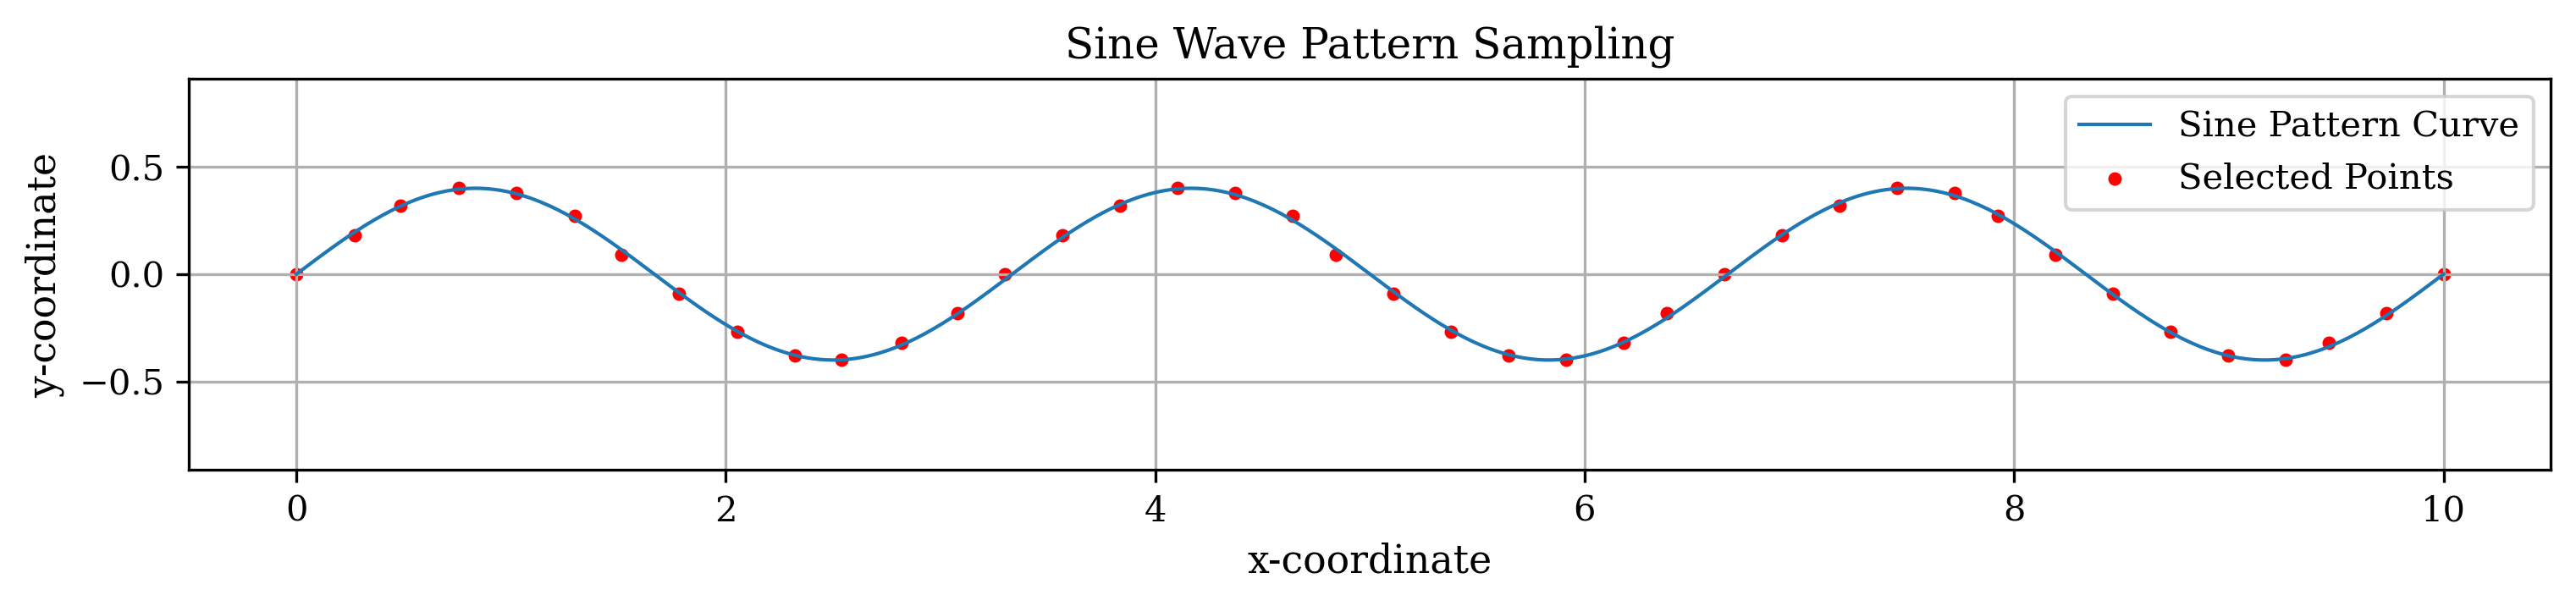

In [5]:
script_name = "ii-PINNs-inverse"
DIRS = setup_output_dirs(script_name)
torch.set_default_dtype(torch.float64) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
df = pd.read_csv("Input/data")
df.columns = df.columns.str.strip()

x_cfd = df["x-coordinate"].to_numpy()
y_cfd = df["y-coordinate"].to_numpy()
u_cfd = df["x-velocity"].to_numpy()
v_cfd = df["y-velocity"].to_numpy()

X_CFD = torch.from_numpy(
    np.column_stack((x_cfd, y_cfd))
).double()

indices, xy_sampled, u_sampled, v_sampled, (x_p, y_p), (xc, yc) = sine_wave_pattern_sampling(
    x_data=x_cfd,
    y_data=y_cfd,
    xy=X_CFD,
    u=u_cfd,
    v=v_cfd,
    n_samples=40,
    save_path=os.path.join(DIRS["plots"], "selected_points.png")
)

In [8]:
class Pinns:
    def __init__(self):
        # Device
        self.device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
        self.network = CNetwork().to(self.device)
        print("CUDA Available:", torch.cuda.is_available())

        # Physical parameters
        self.rho = 1.0        # Density [kg/m³]
        self.eta_0 = 0.01     # Zero-shear viscosity [Pa·s]
        self.eta_inf = 0.005  # Infinite-shear viscosity [Pa·s]
        self.lam = 1.0         # Relaxation time [s]
        self.n_cy = 0.5       # Power-law index
        self.a_cy = 2.0      # Yasuda parameter

        # Geometry
        self.L = 10.0
        self.H = 1.0
        
        # Cylinder parameters
        self.xc = 3.0
        self.yc = 0.0
        self.R = 0.15

        # Domain grid
        self.nx = 150
        self.ny = 30

        dx = self.L / self.nx
        dy = self.H / self.ny

        self.x = torch.arange(0, self.L + dx, dx)
        self.y = torch.arange(-self.H/2, self.H/2 + dy, dy)

        # interior collocation points
        X, Y = torch.meshgrid(self.x, self.y, indexing="ij")
        self.X = torch.stack((X.reshape(-1), Y.reshape(-1)), dim=1)
        self.X = self.X.to(self.device).requires_grad_(True)

        # remove interior points inside cylinder
        dist = torch.sqrt((self.X[:,0]-self.xc)**2 + (self.X[:,1]-self.yc)**2)
        mask = dist > self.R
        self.X = self.X[mask].detach()
        self.X.requires_grad_(True)


        # Boundary points
        dx_b = self.L / 3500
        dy_b = self.H / 350
        
        self.x_b = torch.arange(0, self.L + dx_b, dx_b)
        self.y_b = torch.arange(-self.H/2, self.H/2 + dy_b, dy_b)
        
        # inlet (entire left boundary)
        Xin, Yin = torch.meshgrid(self.x_b[0:1], self.y_b, indexing="ij")
        self.inlet = torch.stack((Xin.reshape(-1), Yin.reshape(-1)), dim=1)
        
        # upper wall
        Xuw, Yuw = torch.meshgrid(self.x_b, self.y_b[-1:], indexing="ij")
        self.uw = torch.stack((Xuw.reshape(-1), Yuw.reshape(-1)), dim=1)
        
        # lower wall
        Xdw, Ydw = torch.meshgrid(self.x_b, self.y_b[0:1], indexing="ij")
        self.dw = torch.stack((Xdw.reshape(-1), Ydw.reshape(-1)), dim=1)

        # cylinder boundary
        n_cyl = 500
        theta = torch.linspace(0, 2*np.pi, n_cyl)
        
        x_cyl = self.xc + self.R * torch.cos(theta)
        y_cyl = self.yc + self.R * torch.sin(theta)
        
        self.cyl = torch.stack((x_cyl, y_cyl), dim=1)        
        
        # velocity BC points
        self.X_train = torch.cat([self.uw, self.dw, self.cyl], dim=0).to(self.device)
        
        # outlet (right boundary)
        Xout, Yout = torch.meshgrid(self.x_b[-1:], self.y_b, indexing="ij")
        self.X_train_p = torch.stack((Xout.reshape(-1), Yout.reshape(-1)), dim=1).to(self.device)
        
        # inverse
        # Boundary condition values
        # inlet parabolic profile
        # u_in = 0.5 * (1.0 -4* self.y_b**2)
        # v_in = torch.zeros_like(u_in)
        # self.uv_inlet = torch.stack((u_in, v_in), dim=1)
        
        # upper wall (no-slip)
        u_uw = torch.zeros(len(self.x_b))
        v_uw = torch.zeros(len(self.x_b))
        self.uv_uw = torch.stack((u_uw, v_uw), dim=1)
        
        # lower wall (no-slip)
        u_dw = torch.zeros(len(self.x_b))
        v_dw = torch.zeros(len(self.x_b))
        self.uv_dw = torch.stack((u_dw, v_dw), dim=1)
        
        # no slip on cylinder
        u_cyl = torch.zeros(n_cyl)
        v_cyl = torch.zeros(n_cyl)
        
        self.uv_cyl = torch.stack((u_cyl, v_cyl), dim=1)
        
        self.uv_train = torch.cat(
            [self.uv_uw, self.uv_dw, self.uv_cyl],
            dim=0
        ).to(self.device)
        
        # outlet pressure
        self.p_train = torch.zeros(self.X_train_p.shape[0], device=self.device)

        # Data
        X_sample = xy_sampled.to(device).double().requires_grad_(True)
        u_sample = torch.from_numpy(u_sampled).to(device).double()
        v_sample = torch.from_numpy(v_sampled).to(device).double()
        self.X_data = X_sample.to(self.device)
        self.u_data = u_sample.to(self.device)
        self.v_data = v_sample.to(self.device)

        # Loss
        self.criterion = nn.MSELoss()

        # Optimizers
        self.adam = torch.optim.Adam(self.network.parameters(), lr=1e-3)

        self.optimizer = torch.optim.LBFGS(
            self.network.parameters(),
            lr=0.01,
            max_iter=2000,
            max_eval=2000,
            history_size=50,
            tolerance_grad=1e-8,
            tolerance_change=1.0 * np.finfo(float).eps,
            line_search_fn="strong_wolfe"
        )

        self.loss_history = []

    # gradient function
    def gradient(self, y, x, index):
        grad = torch.autograd.grad(
            y, x,
            grad_outputs=torch.ones_like(y),
            create_graph=True,
            retain_graph=True,
            only_inputs=True
        )[0]
        return grad[:, index]


    # Loss function
    def loss_f(self):
        # Boundary 
        uv_b = self.network(self.X_train)
        u_b = uv_b[:, 0]
        v_b = uv_b[:, 1]
        
        p_b = self.network(self.X_train_p)[:, 2]
        
        loss_u_b = self.criterion(u_b, self.uv_train[:, 0])
        loss_v_b = self.criterion(v_b, self.uv_train[:, 1])
        loss_p_b = self.criterion(p_b, self.p_train)
        loss_data = loss_u_b + loss_v_b +loss_p_b
    
        # Interior
        uvp = self.network(self.X)
        self.u_P = uvp[:, 0]
        self.v_P = uvp[:, 1]
        self.P_P = uvp[:, 2]
    
        # derivatives
        self.du_dx = self.gradient(self.u_P, self.X, 0)
        self.du_dy = self.gradient(self.u_P, self.X, 1)
        self.du_dxx = self.gradient(self.du_dx, self.X, 0)
        self.du_dyy = self.gradient(self.du_dy, self.X, 1)
    
        self.dv_dx = self.gradient(self.v_P, self.X, 0)
        self.dv_dy = self.gradient(self.v_P, self.X, 1)
        self.dv_dxx = self.gradient(self.dv_dx, self.X, 0)
        self.dv_dyy = self.gradient(self.dv_dy, self.X, 1)
    
        self.dp_dx = self.gradient(self.P_P, self.X, 0)
        self.dp_dy = self.gradient(self.P_P, self.X, 1)

        # Data loss (sampled CFD points)
        uv_data_pred = self.network(self.X_data)
        u_data_pred = uv_data_pred[:, 0]
        v_data_pred = uv_data_pred[:, 1]
        
        loss_u_data = self.criterion(u_data_pred, self.u_data)
        loss_v_data = self.criterion(v_data_pred, self.v_data)
        
        loss_data_samples = loss_u_data + loss_v_data

    
        # Navier-Stokes residuals
        gamma_dot = torch.sqrt(2*self.du_dx**2 + 2*self.dv_dy**2 + (self.du_dy + self.dv_dx)**2 + 1e-12)
        mu = self.eta_inf + (self.eta_0 - self.eta_inf) * \
             (1 + (self.lam * gamma_dot)**self.a_cy)**((self.n_cy - 1)/self.a_cy)
        # stress components
        tau_xx = 2*mu*self.du_dx
        tau_xy = mu*(self.du_dy + self.dv_dx)
        tau_yy = 2*mu*self.dv_dy
        
        # divergence of stress
        dtau_xx_dx = self.gradient(tau_xx, self.X, 0)
        dtau_xy_dy = self.gradient(tau_xy, self.X, 1)
        dtau_xy_dx = self.gradient(tau_xy, self.X, 0)
        dtau_yy_dy = self.gradient(tau_yy, self.X, 1)

        # Navier-Stokes equations residuals
        continuity = self.du_dx + self.dv_dy
        momentum_x = self.rho * (self.u_P * self.du_dx + self.v_P * self.du_dy) \
             + self.dp_dx \
             - (dtau_xx_dx + dtau_xy_dy)
        momentum_y = self.rho * (self.u_P * self.dv_dx + self.v_P * self.dv_dy) \
             + self.dp_dy \
             - (dtau_xy_dx + dtau_yy_dy)
    
        loss_continuity = self.criterion(continuity, torch.zeros_like(continuity))
        loss_momentum_x = self.criterion(momentum_x, torch.zeros_like(momentum_x))
        loss_momentum_y = self.criterion(momentum_y, torch.zeros_like(momentum_y))
    
        loss_pde = loss_continuity + loss_momentum_x + loss_momentum_y
        loss_total = loss_data + loss_pde + 10 * loss_data_samples
    
        return loss_total, loss_data, loss_continuity, loss_momentum_x, loss_momentum_y
    
    # Training loop
    def train(self, num_epochs=5000):
        self.network.train()
        run_number    = get_next_run_number(script_name)
        model_path    = os.path.join(DIRS["models"],  "model_best.pth")
        history_path  = os.path.join(DIRS["history"], f"loss_history_run{run_number:03d}.csv")
        time_path = os.path.join(DIRS["history"], f"adam_epoch_time_run{run_number:03d}.csv")
        print(f"Run {run_number:03d}")
        print(f"   Model   -> {model_path}  (overwrites previous)")
        print(f"   History -> {history_path}")
        epoch_times = []
        checkpoint_path = "pinns_checkpoint.pth"
    
        for i in range(num_epochs):
            start_time = time.time()
            self.adam.zero_grad()
            loss_total, loss_data, loss_continuity, loss_momentum_x, loss_momentum_y = self.loss_f()
            loss_total.backward()
            self.adam.step()
    
            self.loss_history.append({"epoch": i, "loss_total": loss_total.item()})
            epoch_duration = time.time() - start_time
            epoch_times.append({"epoch": i, "duration": epoch_duration})    
            if i % 10 == 0:
                print(f"Epoch {i}: Total Loss={loss_total.item():.3e}, "
                      f"Boundary Loss={loss_data.item():.3e}, "
                      f"Continuity Loss={loss_continuity.item():.3e}, "
                      f"Momentum X Loss={loss_momentum_x.item():.3e}, "
                      f"Momentum Y Loss={loss_momentum_y.item():.3e}")
            if i % 100 == 0:
                torch.save(self.network.state_dict(), model_path)
                print(f"  Checkpoint saved -> {model_path}")
                
        df_time = pd.DataFrame(epoch_times)
        df_time.to_csv(time_path, index=False)
        print(f"Adam epoch times saved -> {time_path}")
                
        # LBFGS phase
        lbfgs_step = [0]
        adam_epochs  = num_epochs    
    
    def plot(self, nx_plot=300, ny_plot=100):
        self.network.eval()
    
        # 1. Regular grid for PINN predictions
        x_plot = torch.linspace(0, self.L, nx_plot, device=self.device)
        y_plot = torch.linspace(-self.H / 2, self.H / 2, ny_plot, device=self.device)
        Xg, Yg = torch.meshgrid(x_plot, y_plot, indexing='ij')
        xy_grid = torch.stack([Xg.flatten(), Yg.flatten()], dim=1).double()
    
        with torch.no_grad():
            uvp_pred = self.network(xy_grid)
            u_pred = uvp_pred[:, 0]
            v_pred = uvp_pred[:, 1]
            p_pred = uvp_pred[:, 2]
    
        # Prepare for plotting
        u_grid = u_pred.detach().cpu().reshape(nx_plot, ny_plot).numpy()
        v_grid = v_pred.detach().cpu().reshape(nx_plot, ny_plot).numpy()
        p_grid = p_pred.detach().cpu().reshape(nx_plot, ny_plot).numpy()
    
        X_np = Xg.cpu().numpy()
        Y_np = Yg.cpu().numpy()
    
        # Use cylinder parameters from self
        xc = self.xc
        yc = self.yc
        R = self.R
    
        # --------- Cylinder mask function ---------
        def get_cylinder_mask(X, Y):
            return (X - xc) ** 2 + (Y - yc) ** 2 <= R ** 2
    
        cylinder_mask = get_cylinder_mask(X_np, Y_np)
    
        # 2. Compute viscosity
        xy_grid_grad = xy_grid.clone().detach().requires_grad_(True)
        uvp = self.network(xy_grid_grad)
        u = uvp[:, 0]
        v = uvp[:, 1]
        p = uvp[:, 2]
        du_dx = self.gradient(u, xy_grid_grad, 0)
        du_dy = self.gradient(u, xy_grid_grad, 1)
        dv_dx = self.gradient(v, xy_grid_grad, 0)
        dv_dy = self.gradient(v, xy_grid_grad, 1)
        gamma_dot = torch.sqrt(2*du_dx**2 + 2*dv_dy**2 + (du_dy + dv_dx)**2 + 1e-12)
        eta_pinn = self.eta_inf + (self.eta_0 - self.eta_inf) * \
                (1 + (self.lam * gamma_dot) ** self.a_cy) ** ((self.n_cy - 1) / self.a_cy)
        eta_grid = eta_pinn.detach().cpu().reshape(nx_plot, ny_plot).numpy()
    
        # 3. Load CFD reference data
        df = pd.read_csv("Input/data")
        df.columns = df.columns.str.strip()
    
        x_cfd = df["x-coordinate"].values
        y_cfd = df["y-coordinate"].values
        u_cfd = df["x-velocity"].values
        v_cfd = df["y-velocity"].values
        p_cfd = df["pressure"].values
        viscosity_cfd = df["viscosity-lam"].values
    
        # 4. Interpolate CFD data onto regular grid
        from scipy.interpolate import griddata
        u_cfd_grid = griddata((x_cfd, y_cfd), u_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
        v_cfd_grid = griddata((x_cfd, y_cfd), v_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
        p_cfd_grid = griddata((x_cfd, y_cfd), p_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
        eta_cfd_grid = griddata((x_cfd, y_cfd), viscosity_cfd, (X_np, Y_np), method='linear', fill_value=np.nan)
    
        # 5. Mask all fields (PINN & CFD) inside cylinder
        for grid in [u_grid, v_grid, p_grid, eta_grid, u_cfd_grid, v_cfd_grid, p_cfd_grid, eta_cfd_grid]:
            grid[cylinder_mask] = np.nan
    
        # 6. PINN on CFD points (for error)
        xy_cfd_torch = torch.from_numpy(np.column_stack((x_cfd, y_cfd))).to(self.device).double()
        with torch.no_grad():
            uvp_pinn_cfd = self.network(xy_cfd_torch)
            u_pinn_cfd = uvp_pinn_cfd[:, 0].detach().cpu().numpy()
            v_pinn_cfd = uvp_pinn_cfd[:, 1].detach().cpu().numpy()
            p_pinn_cfd = uvp_pinn_cfd[:, 2].detach().cpu().numpy()
    
        # Viscosity from PINN at CFD points
        xy_cfd_torch.requires_grad_(True)
        uvp_pp = self.network(xy_cfd_torch)
        u_pp = uvp_pp[:, 0]
        v_pp = uvp_pp[:, 1]
        du_dx_pp = self.gradient(u_pp, xy_cfd_torch, 0)
        du_dy_pp = self.gradient(u_pp, xy_cfd_torch, 1)
        dv_dx_pp = self.gradient(v_pp, xy_cfd_torch, 0)
        dv_dy_pp = self.gradient(v_pp, xy_cfd_torch, 1)
        gamma_dot_pp = torch.sqrt(2*du_dx_pp**2 + 2*dv_dy_pp**2 + (du_dy_pp + dv_dx_pp)**2 + 1e-12)
        eta_pinn_cfd = self.eta_inf + (self.eta_0 - self.eta_inf) * \
            (1 + (self.lam * gamma_dot_pp) ** self.a_cy) ** ((self.n_cy - 1) / self.a_cy)
        eta_pinn_cfd = eta_pinn_cfd.detach().cpu().numpy().flatten()
    
        # 7. Compute errors
        eps = 1e-12
        u_range = u_cfd.max() - u_cfd.min() + eps
        v_range = np.abs(v_cfd).max() + eps
        p_range = p_cfd.max() - p_cfd.min() + eps
        eta_range = viscosity_cfd.max() - viscosity_cfd.min() + eps
    
        rel_err_u = 100.0 * np.abs(u_pinn_cfd - u_cfd) / u_range
        rel_err_v = 100.0 * np.abs(v_pinn_cfd - v_cfd) / v_range
        rel_err_p = 100.0 * np.abs((p_pinn_cfd - p_pinn_cfd.min()) - (p_cfd - p_cfd.min())) / p_range
    
        def compute_l2_error(pred, ref):
            mask = ~np.isnan(ref)
            return 100.0 * np.linalg.norm(pred[mask] - ref[mask]) / (np.linalg.norm(ref[mask]) + 1e-12)
    
        l2_u = compute_l2_error(u_pinn_cfd, u_cfd)
        l2_v = compute_l2_error(v_pinn_cfd, v_cfd)
        l2_p = compute_l2_error(p_pinn_cfd - p_pinn_cfd.min(), p_cfd - p_cfd.min())
    
        # --------- Helper functions ---------
    
        def contour_plot(data, title, fname, label, cmap="jet"):
            fpath = os.path.join(DIRS["plots"], fname)
            plt.figure(figsize=(12, 2))

            data_masked = np.ma.masked_invalid(data)
            cf = plt.contourf(X_np, Y_np, data_masked, levels=80, cmap=cmap)
            cbar = plt.colorbar(cf, label=label)
            cbar.ax.locator_params(nbins=5)
            # draw cylinder
            theta = np.linspace(0, 2 * np.pi, 300)
            x_c = xc + R * np.cos(theta)
            y_c = yc + R * np.sin(theta)
            plt.plot(x_c, y_c, 'k', linewidth=2)
            plt.xlabel("x [m]")
            plt.ylabel("y [m]")
            plt.title(title)
            plt.tight_layout()
            plt.savefig(fpath, dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()
    
        def tricontour_plot(x, y, values, title, fname, label, cmap="jet"):
            fpath = os.path.join(DIRS["plots"], fname)
        
            plt.figure(figsize=(12, 2.3))
        
            # Remove CFD points inside cylinder
            mask = (x - xc)**2 + (y - yc)**2 > R**2
            x_plot = x[mask]
            y_plot = y[mask]
            v_plot = values[mask]
        
            cf = plt.tricontourf(x_plot, y_plot, v_plot, levels=80, cmap=cmap)
            plt.colorbar(cf, label=label)
        
            # Draw black outline of cylinder
            theta = np.linspace(0, 2*np.pi, 300)
            x_c = xc + R*np.cos(theta)
            y_c = yc + R*np.sin(theta)
            plt.plot(x_c, y_c, 'k', linewidth=2)
            from matplotlib.patches import Circle
            ax = plt.gca()
            circle = Circle((xc, yc), R, color='white', zorder=100)
            ax.add_patch(circle)
        
            plt.xlabel("x [m]")
            plt.ylabel("y [m]")
            plt.title(title)
        
            plt.tight_layout()
            plt.savefig(fpath, dpi=300, bbox_inches='tight')
            plt.show()
            plt.close()



        # --- Plot PINN predicted fields ---
        contour_plot(u_grid, f"PINN: x-velocity (u)", "u_pinn.png", "u [m/s]")
        contour_plot(v_grid, f"PINN: y-velocity (v)", "v_pinn.png", "v [m/s]")
        contour_plot(p_grid, f"PINN: Pressure (p)", "p_pinn.png", "p [Pa]")
        contour_plot(eta_grid, f"PINN: Viscosity (η)", "viscosity_pinn.png", "η [Pa·s]")
    
        # --- Plot CFD reference fields (interpolated) ---
        contour_plot(u_cfd_grid, f"CFD Reference: x-velocity (u)", "u_cfd.png", "u [m/s]")
        contour_plot(v_cfd_grid, f"CFD Reference: y-velocity (v)", "v_cfd.png", "v [m/s]")
        contour_plot(p_cfd_grid, f"CFD Reference: Pressure (p)", "p_cfd.png", "p [Pa]")
        contour_plot(eta_cfd_grid, f"CFD Reference: Viscosity (η)", "viscosity_cfd.png", "η [Pa·s]")
    
        # --- Plot relative error fields (CFD points only) ---
        tricontour_plot(x_cfd, y_cfd, rel_err_u, f"Relative Error in u-velocity (%)\nL2={l2_u:.2f}%", "error_u_rel.png", "Error [%]", cmap="viridis")
        tricontour_plot(x_cfd, y_cfd, rel_err_v, f"Relative Error in v-velocity (%)\nL2={l2_v:.2f}%", "error_v_rel.png", "Error [%]", cmap="viridis")
        tricontour_plot(x_cfd, y_cfd, rel_err_p, f"Relative Error in Pressure (%)\nL2={l2_p:.2f}%", "error_p_rel.png", "Error [%]", cmap="viridis")
    

        # 10. Velocity profile at inlet (x = 0)

        ny_prof = 200
        y_prof = torch.linspace(-self.H/2, self.H/2, ny_prof, device=self.device).double()
        x_prof = torch.zeros_like(y_prof)
        xy_inlet = torch.stack([x_prof, y_prof], dim=1)
    
        with torch.no_grad():
            uvp_pinn_in = self.network(xy_inlet)
            u_pinn_in = uvp_pinn_in[:, 0]
            v_pinn_in = uvp_pinn_in[:, 1]
            p_pinn_in = uvp_pinn_in[:, 2]
    
        y_np = y_prof.cpu().numpy()
        u_pinn_np = u_pinn_in.detach().cpu().numpy().flatten()
        u_target = 1.5 * (1.0 -4* y_np**2)
        fpath = os.path.join(DIRS["plots"], "u_profile_x0.png")
    
        plt.figure(figsize=(4, 6))
        plt.plot(u_pinn_np, y_np, 'r-', lw=2, label='PINN')
        plt.plot(u_target, y_np, 'k--', lw=2, label='Inlet profile')
        plt.xlabel('u [m/s]')
        plt.ylabel('y [m]')
        plt.title('Velocity profile at x = 0')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(fpath, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

CUDA Available: True
Run 001
   Model   -> ii-PINNs-inverse-Results/models/model_best.pth  (overwrites previous)
   History -> ii-PINNs-inverse-Results/history/loss_history_run001.csv
Epoch 0: Total Loss=1.238e+00, Boundary Loss=4.347e-02, Continuity Loss=8.624e-03, Momentum X Loss=8.773e-04, Momentum Y Loss=2.023e-03
  Checkpoint saved -> ii-PINNs-inverse-Results/models/model_best.pth


/tmp/ipykernel_2088969/549885323.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.network.load_state_dict(torch.load(os.path.join(DIRS["models"], "model_best.pth")))


Epoch 10: Total Loss=3.777e-01, Boundary Loss=6.123e-02, Continuity Loss=1.114e-03, Momentum X Loss=7.305e-04, Momentum Y Loss=1.302e-03
Epoch 20: Total Loss=3.158e-01, Boundary Loss=1.323e-01, Continuity Loss=7.282e-04, Momentum X Loss=2.068e-04, Momentum Y Loss=3.899e-04
Epoch 30: Total Loss=2.690e-01, Boundary Loss=8.121e-02, Continuity Loss=3.687e-04, Momentum X Loss=9.985e-05, Momentum Y Loss=2.213e-04
Epoch 40: Total Loss=2.566e-01, Boundary Loss=8.542e-02, Continuity Loss=1.795e-04, Momentum X Loss=7.888e-05, Momentum Y Loss=1.749e-04
Epoch 50: Total Loss=2.534e-01, Boundary Loss=9.817e-02, Continuity Loss=3.335e-04, Momentum X Loss=7.113e-05, Momentum Y Loss=1.211e-04
Epoch 60: Total Loss=2.494e-01, Boundary Loss=9.425e-02, Continuity Loss=3.436e-04, Momentum X Loss=7.272e-05, Momentum Y Loss=9.269e-05
Epoch 70: Total Loss=2.475e-01, Boundary Loss=9.145e-02, Continuity Loss=3.757e-04, Momentum X Loss=7.298e-05, Momentum Y Loss=7.787e-05
Epoch 80: Total Loss=2.464e-01, Boundary 

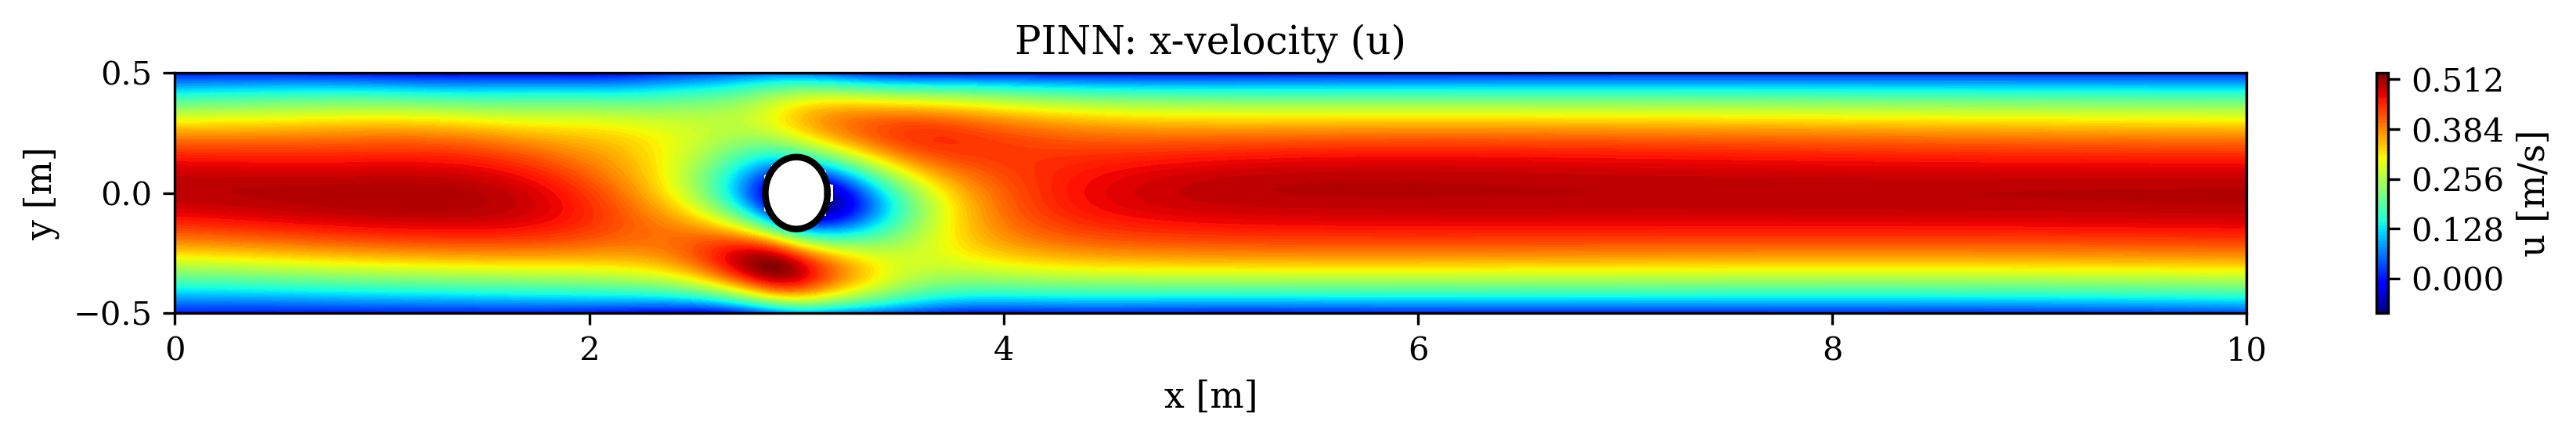

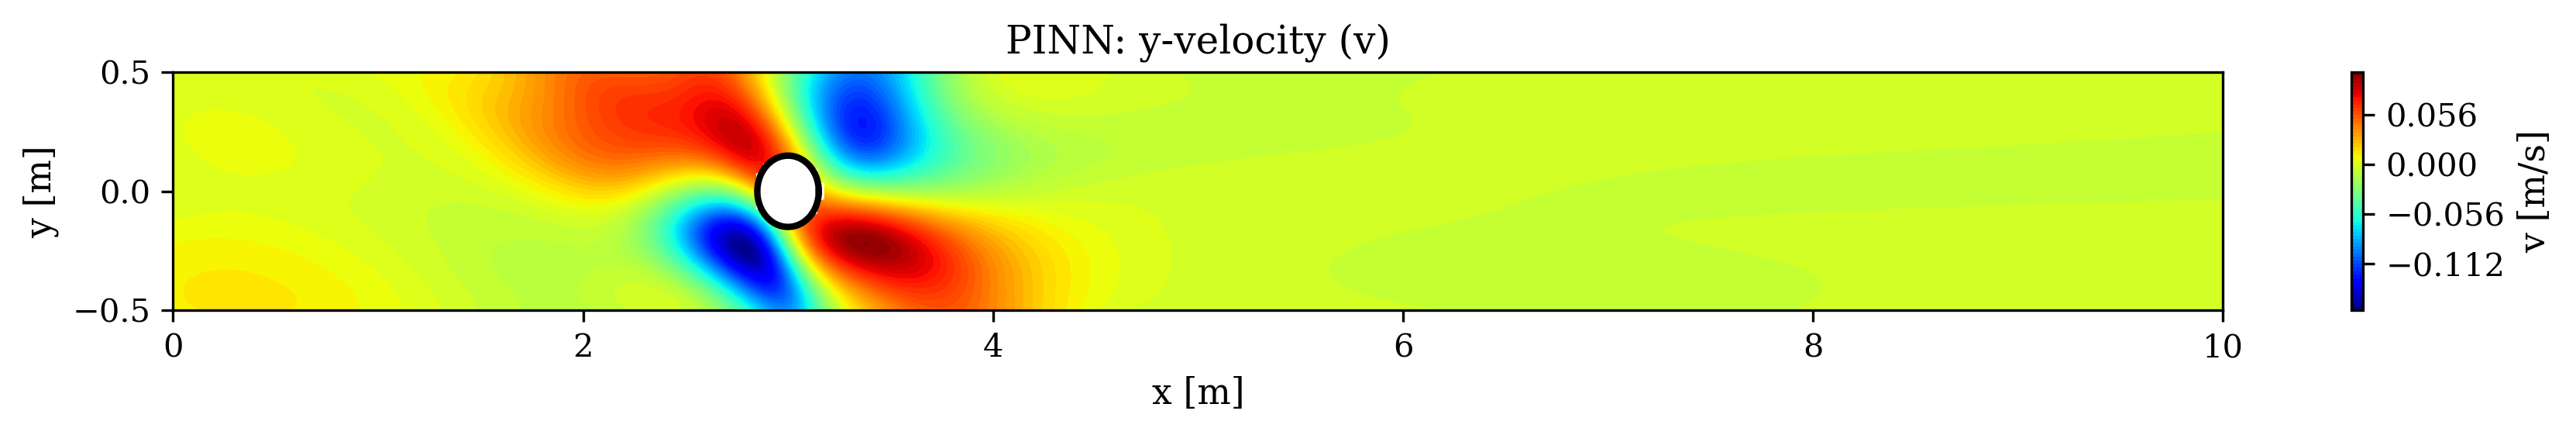

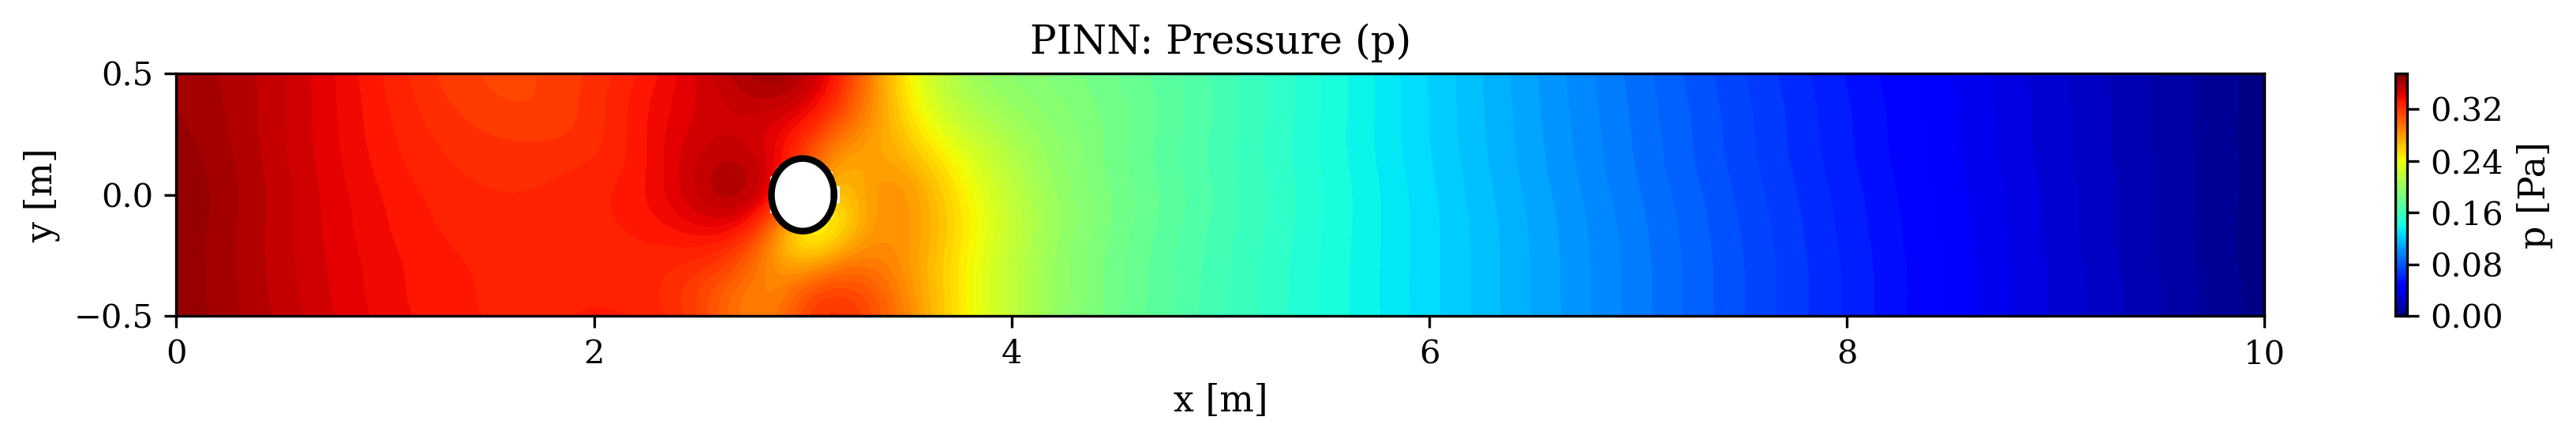

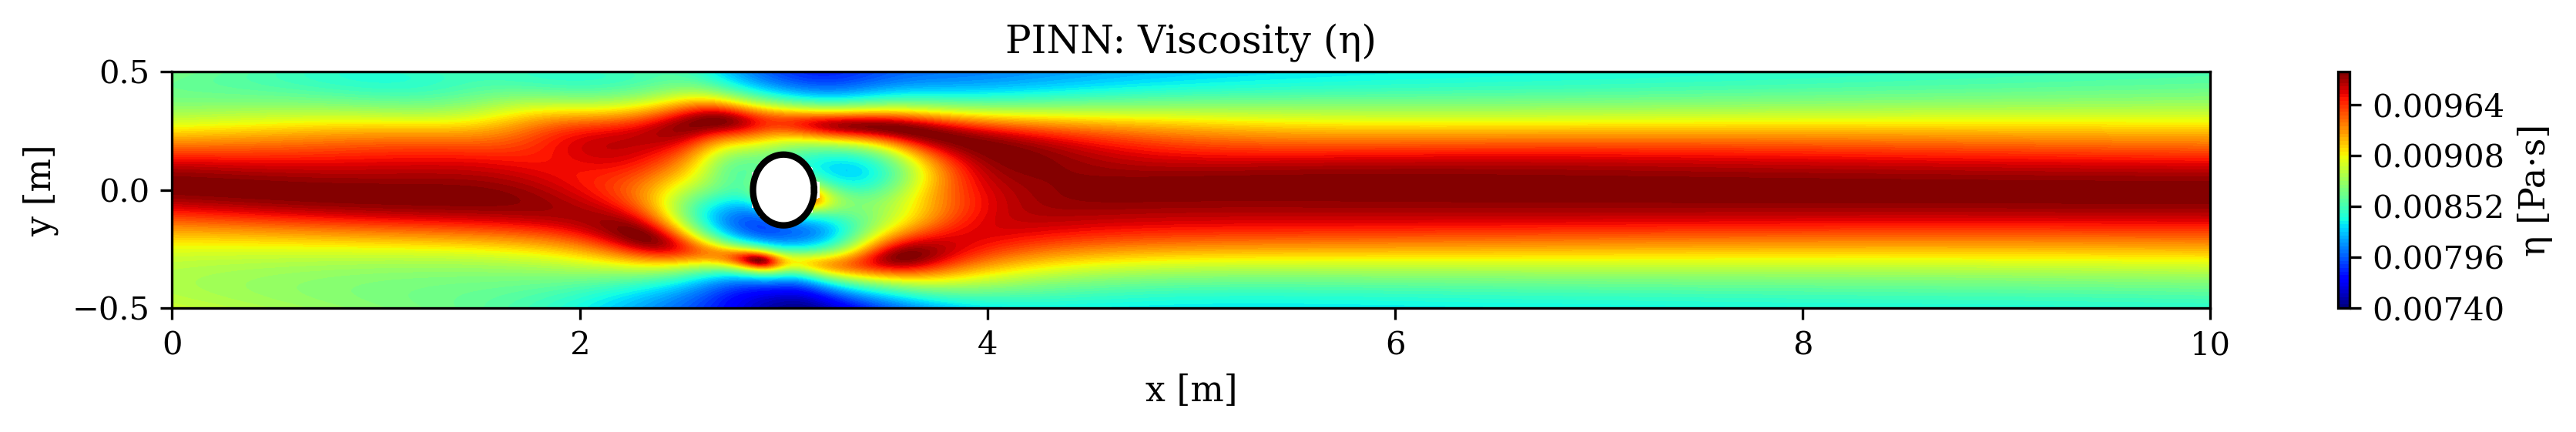

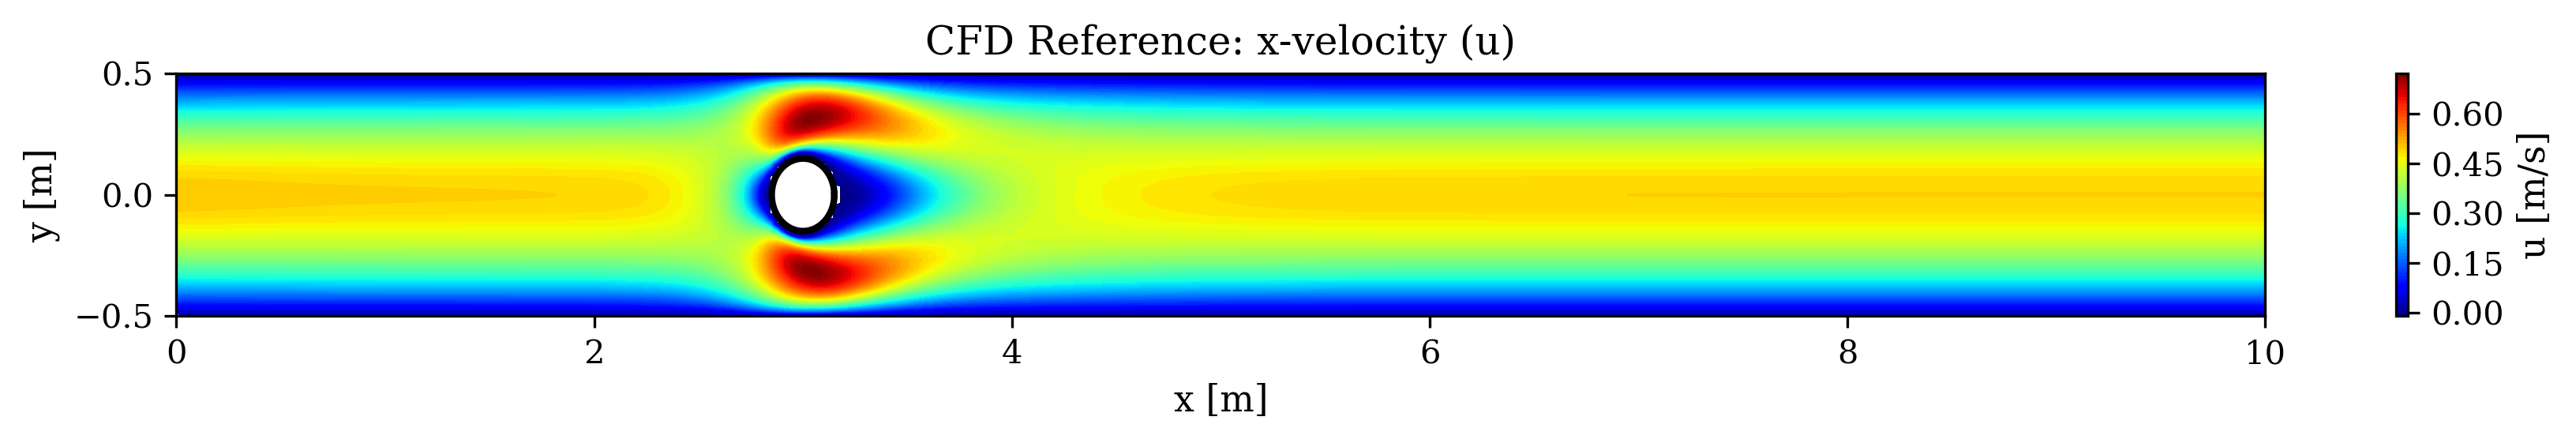

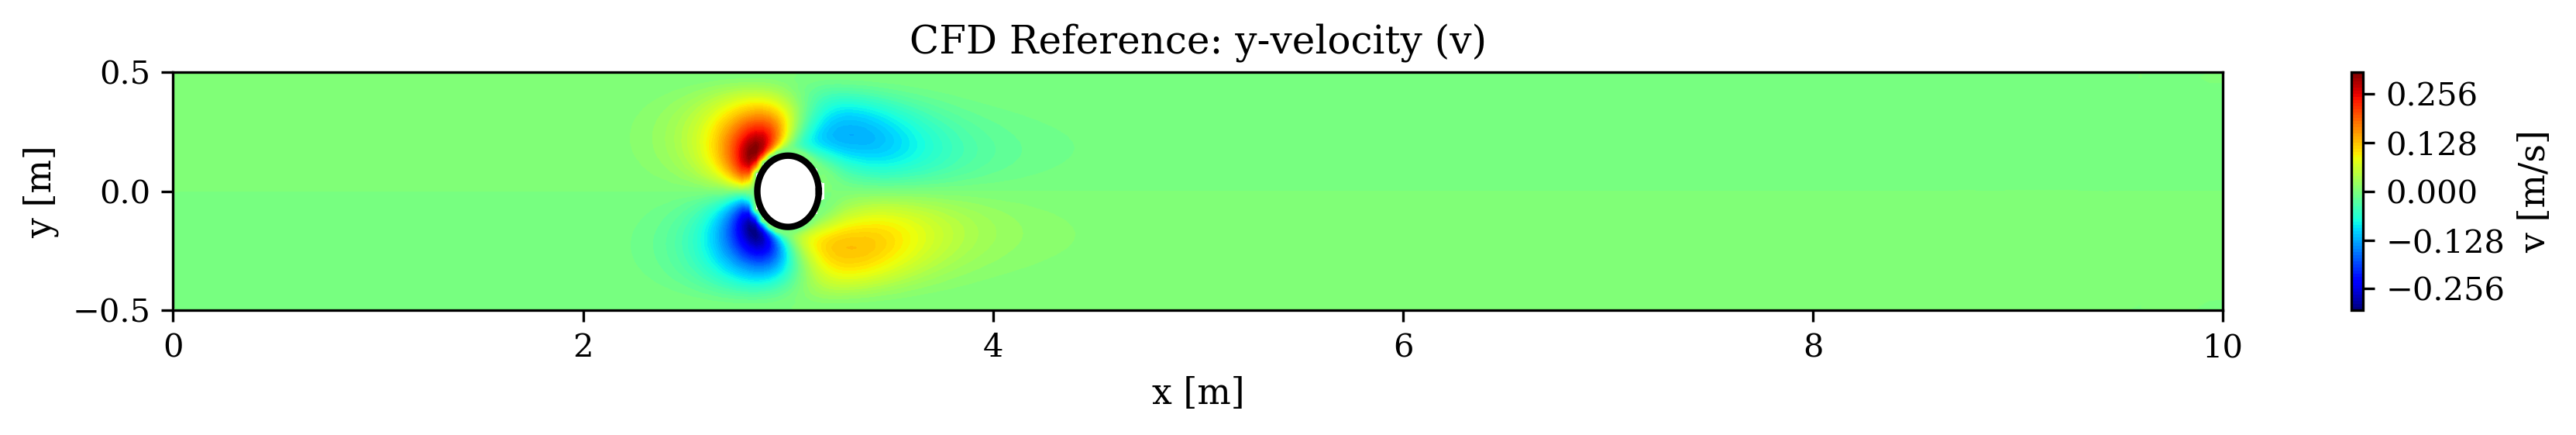

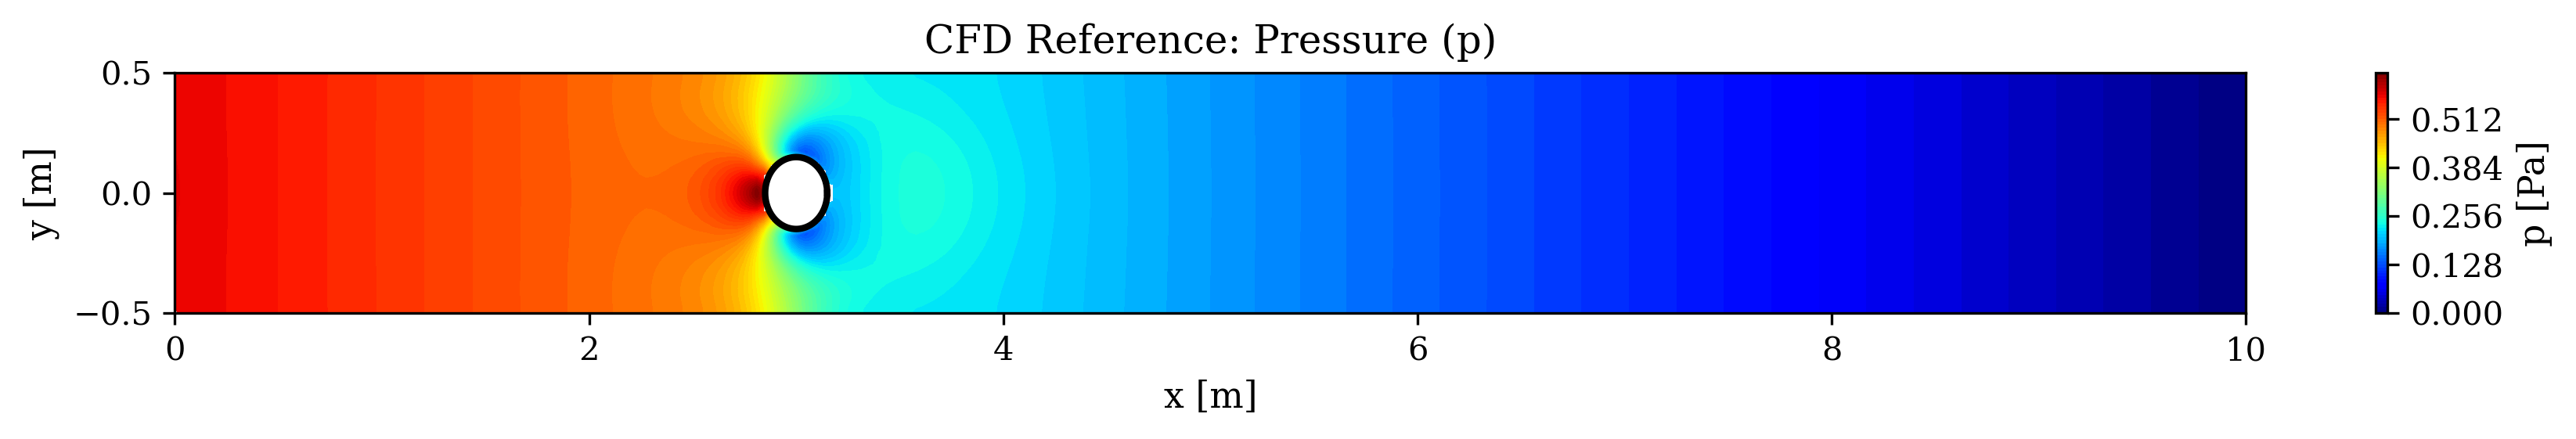

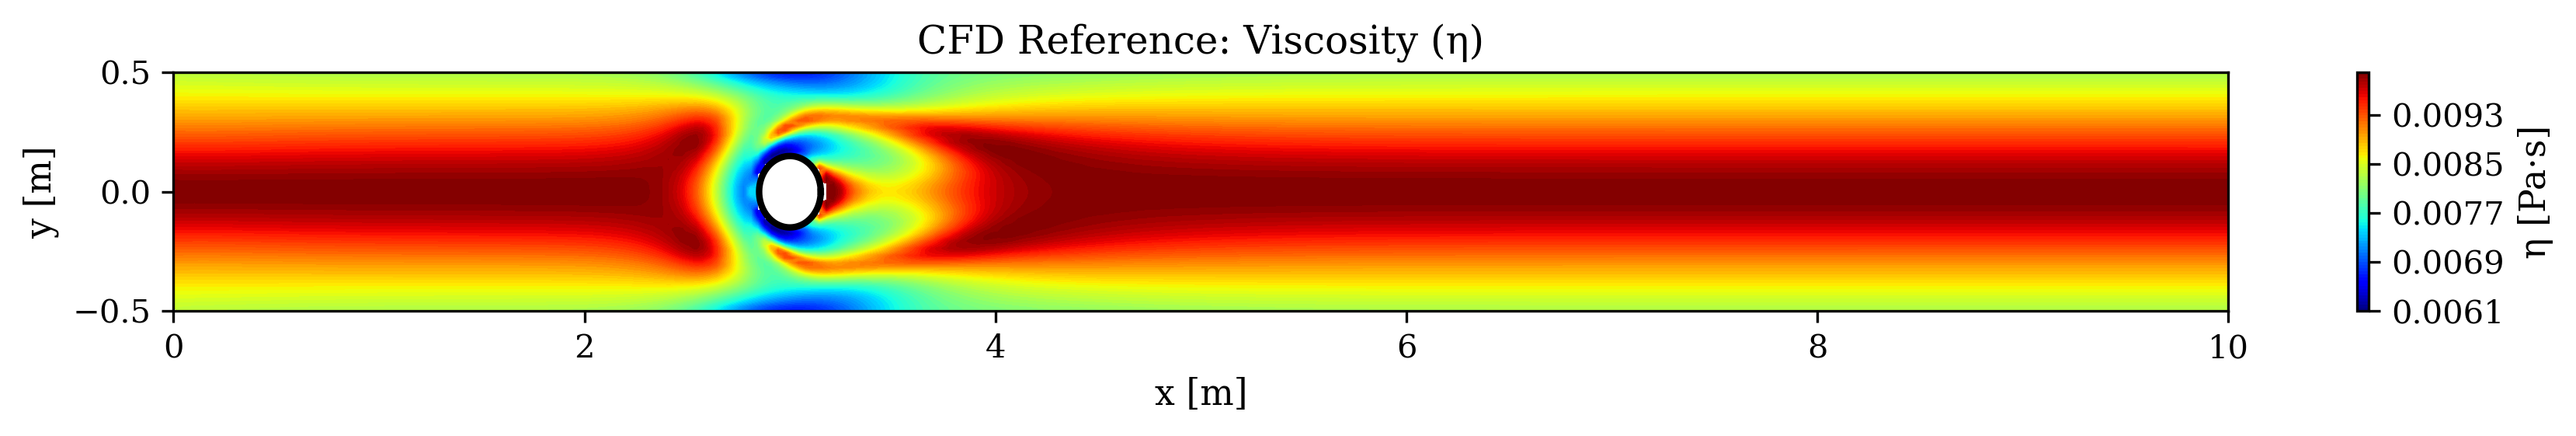

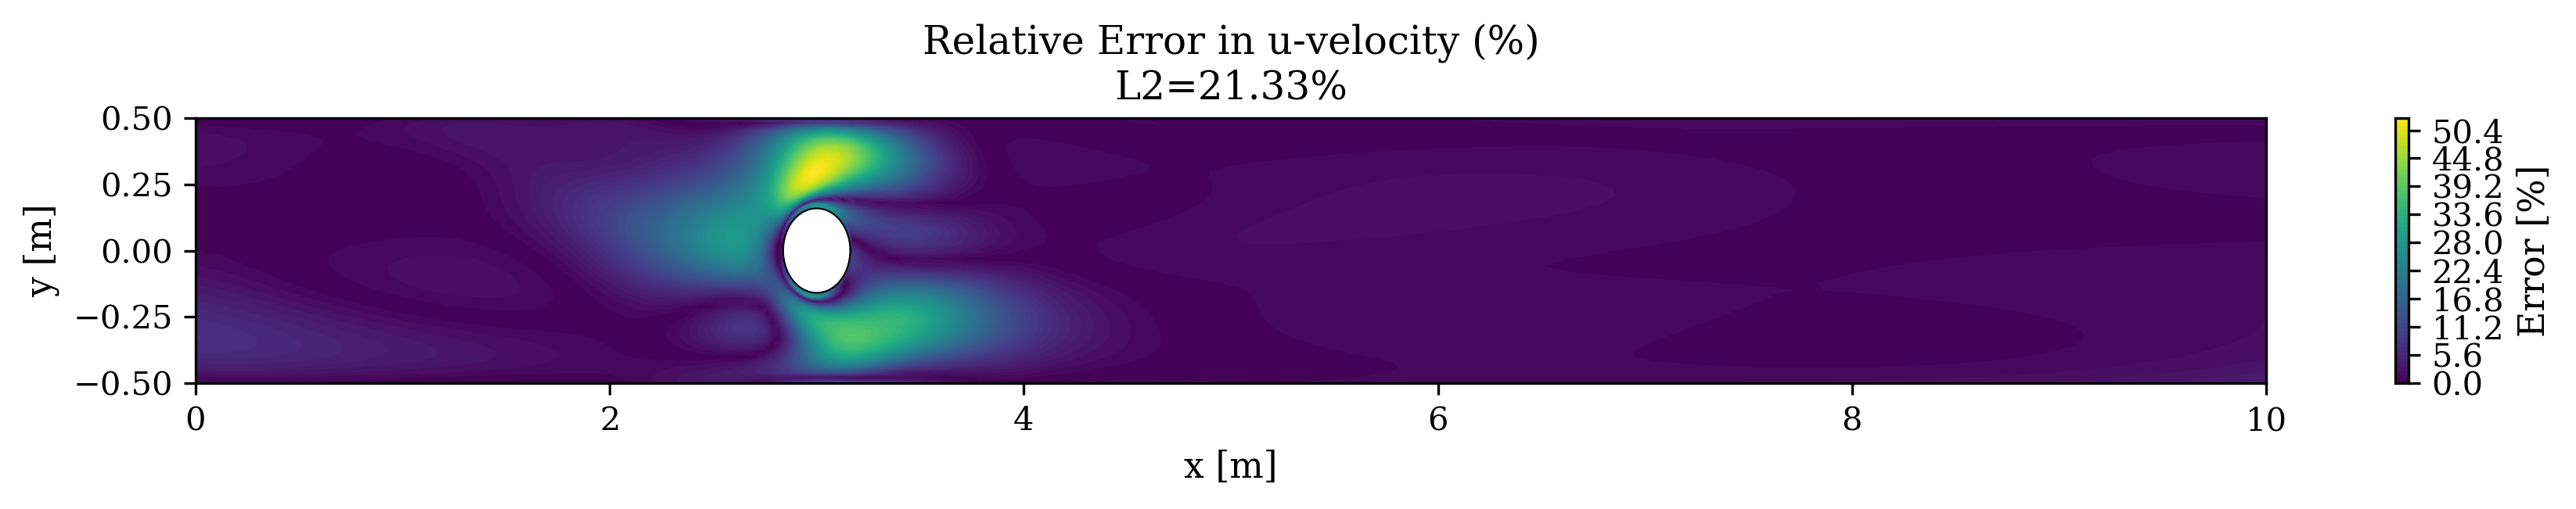

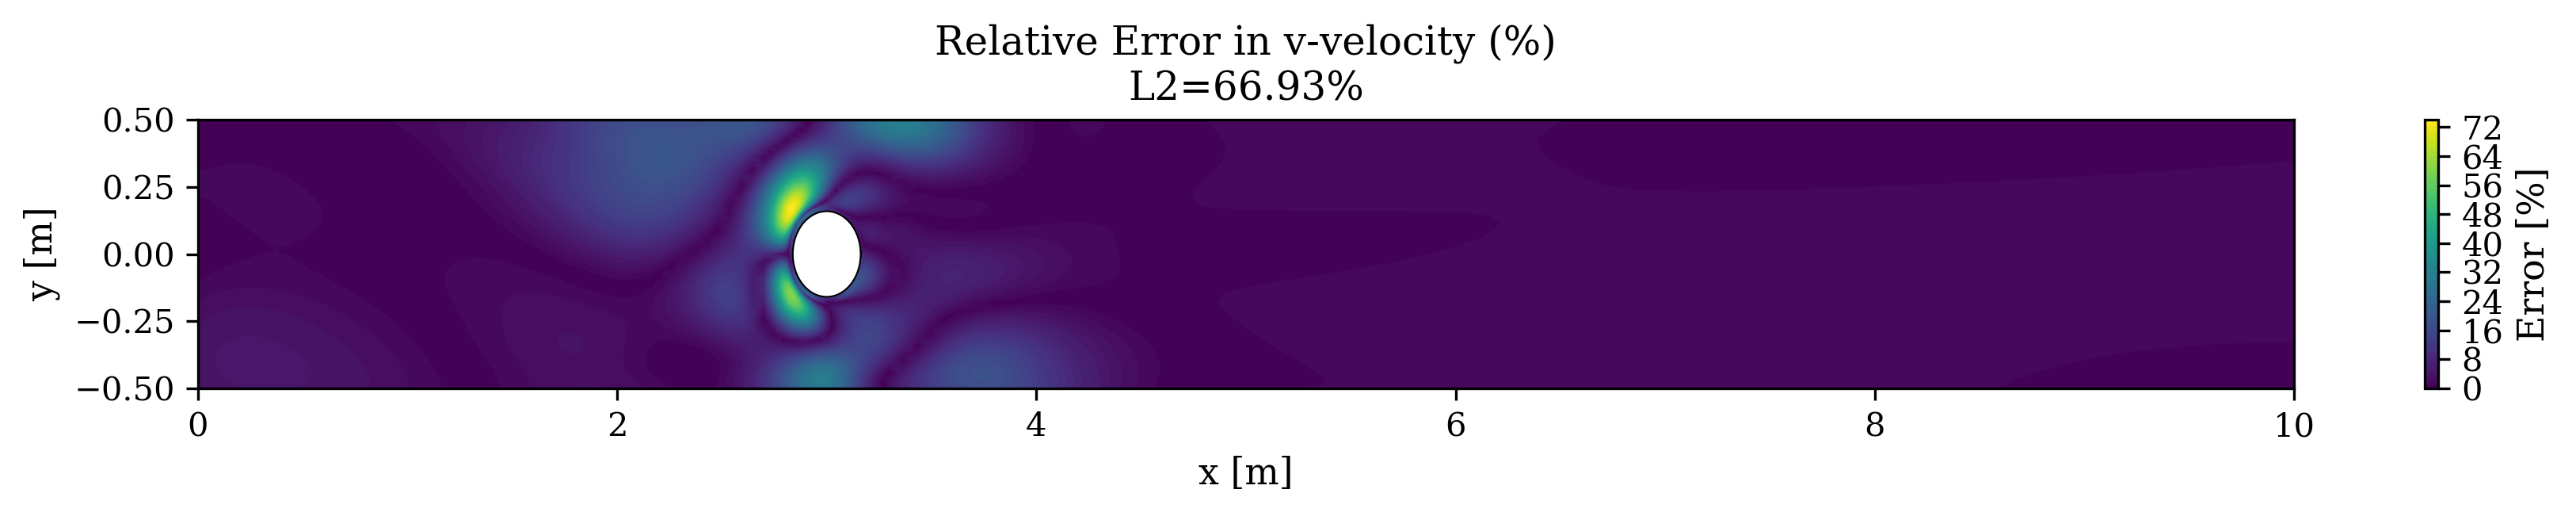

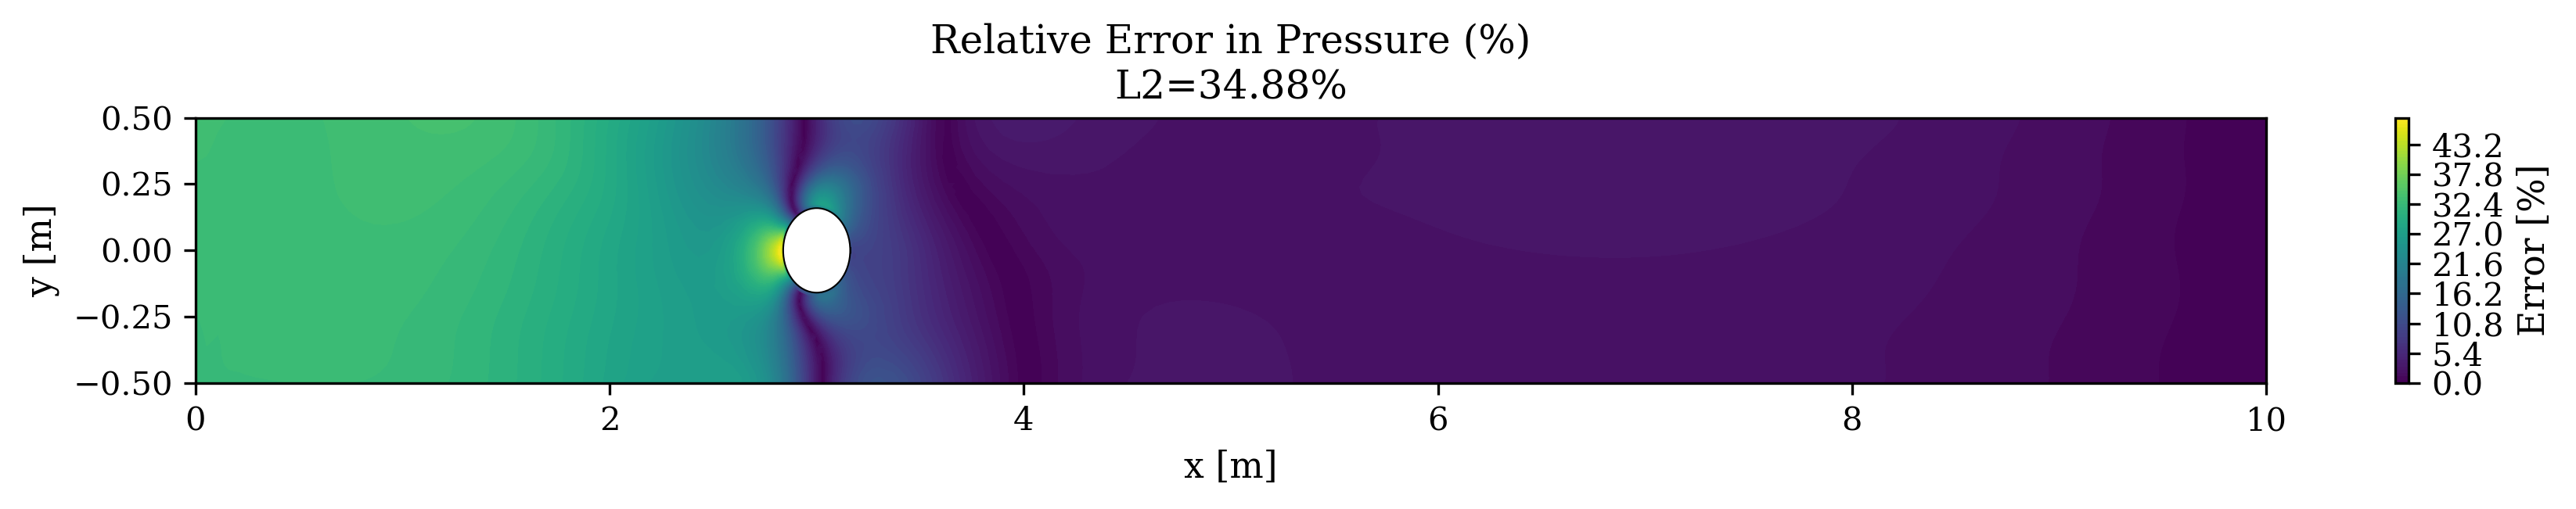

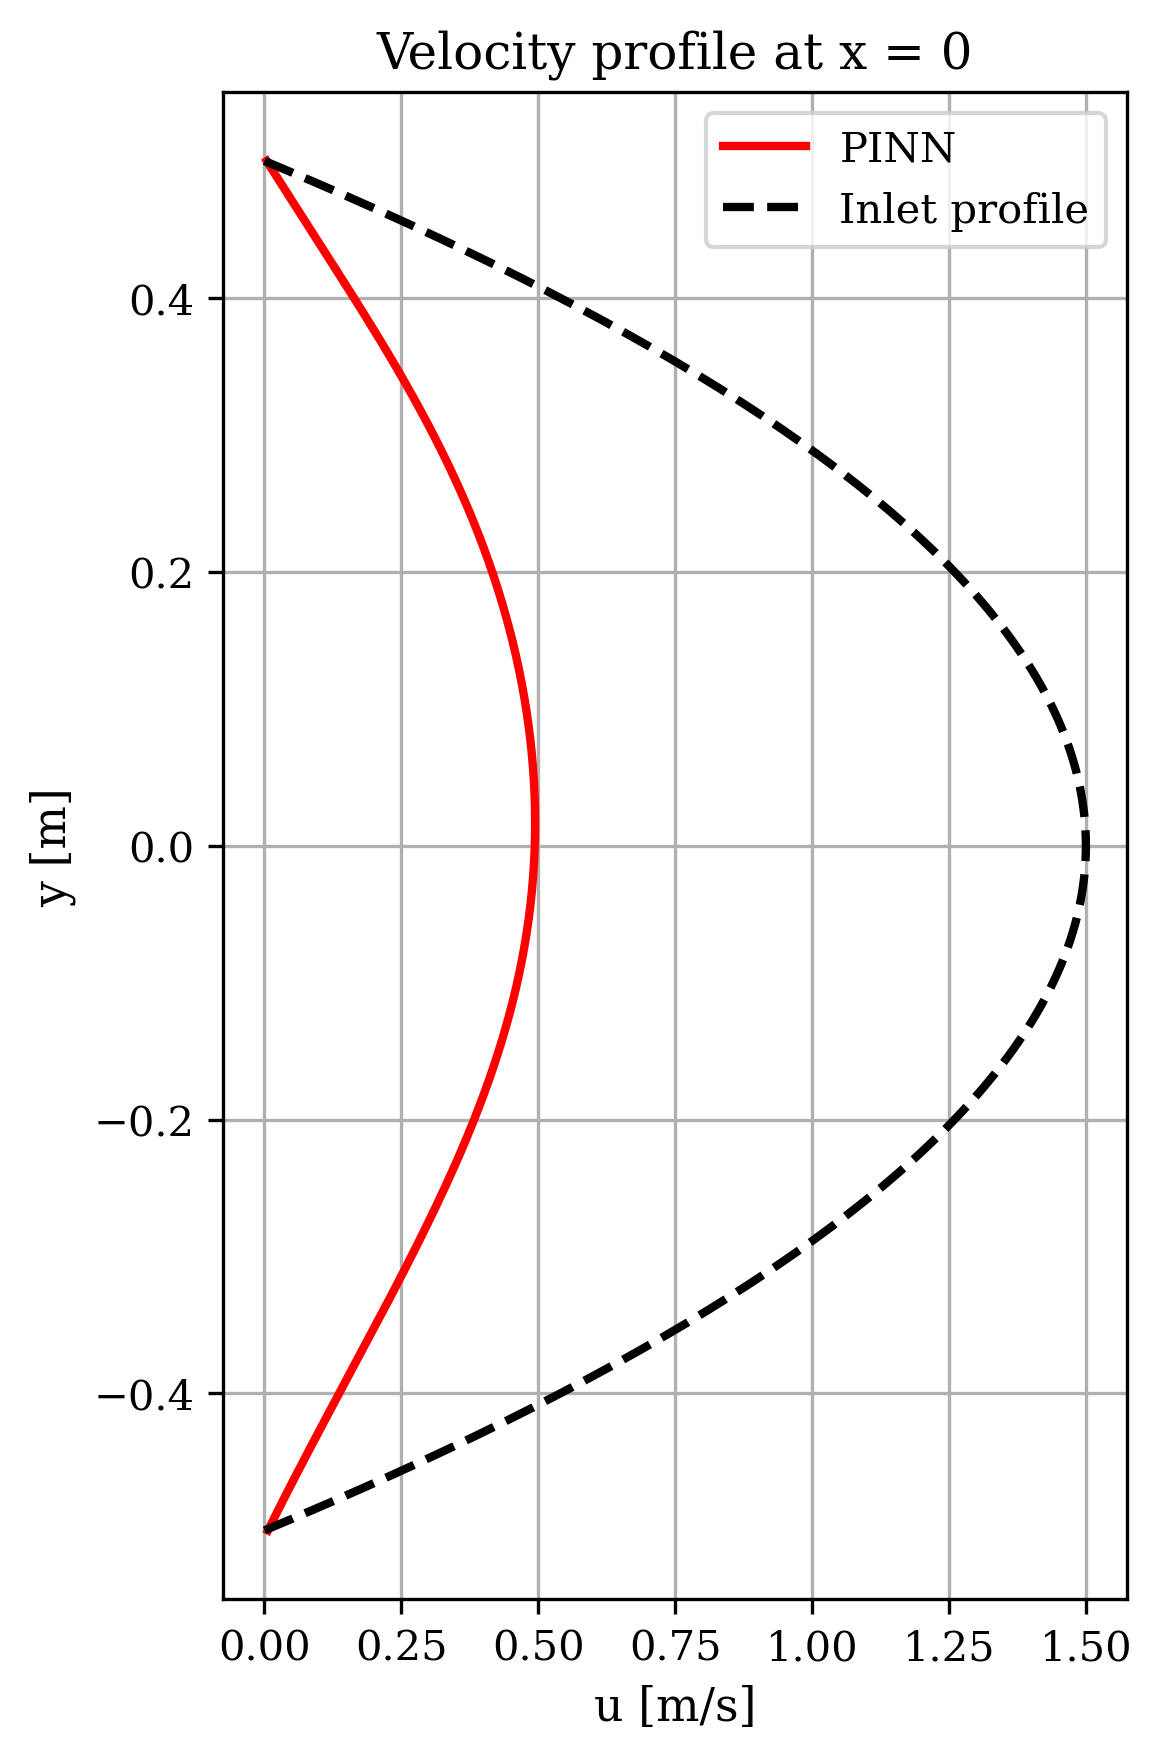

In [9]:
net = Pinns()
net.network.load_state_dict(torch.load(os.path.join(DIRS["models"], "model_best.pth")))
net.train(num_epochs=10000)
net.plot()

In [3]:
import shutil
import os
folder_path = 'ii-PINNs-inverse-Results'
#shutil.rmtree(folder_path)